In [ ]:
# ============================================
# Standard Detection Dataset EDA (1 to 13)
# Birdfeeder / Hummingbird Detection
# ============================================
# This notebook covers:
#  1) File integrity
#  2) Image properties
#  3) Duplicates + near-duplicates
#  4) Slices (day/night, blur, etc.)
#  5) Label coverage + background ratio
#  6) Class distribution (image-level + box-level)
#  7) Box geometry stats (area, aspect, centers, pixel size)
#  8) Label validity checks
#  9) Annotation completeness heuristics
# 10) Split sanity (val/test positives, balance)
# 11) Leakage detection (duplicates across splits)
# 12) Classifier vs detector viability
# 13) Suggested training recipe (imgsz, model size, aug hints)
#
# Outputs:
# - EDA reports in ROOT/_eda_reports/
# - CSV inventories + duplicate reports
# - Plots for quick decisions
# ============================================

In [1]:
# ---- Cell 1: Imports ----
import os
import math
import hashlib
import random
from pathlib import Path
from typing import Dict, List, Tuple, Optional
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps, ExifTags
from pathlib import Path

In [2]:
# ---- Cell 2: Config ----
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    cur = start.resolve()
    for _ in range(8):  # don't walk forever
        if (cur / "humming_bird_detection").exists() and (cur / "notebooks").exists():
            return cur
        cur = cur.parent
    raise RuntimeError("Could not locate repo root (expected folders: humming_bird_detection/ and notebooks/)")

REPO_ROOT = find_repo_root(Path.cwd())

# Updated paths to match your actual data structure
ROOT = REPO_ROOT / "humming_bird_detection" / "data" / "raw" / "Label Birdfeeder Camera Observations.v3i.yolov11"
IMG_DIR = ROOT / "train" / "images"
LBL_DIR = ROOT / "train" / "labels"

# Also check for valid/test splits if they exist
VAL_IMG_DIR = ROOT / "valid" / "images" if (ROOT / "valid" / "images").exists() else None
VAL_LBL_DIR = ROOT / "valid" / "labels" if (ROOT / "valid" / "labels").exists() else None
TEST_IMG_DIR = ROOT / "test" / "images" if (ROOT / "test" / "images").exists() else None
TEST_LBL_DIR = ROOT / "test" / "labels" if (ROOT / "test" / "labels").exists() else None

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# If you have splits already, set SPLIT_ROOT to your processed dataset root:
# e.g. /.../hb_ready where train/images val/images test/images exist
SPLIT_ROOT = None  # Path("/scratch/.../hb_ready")  # set if you want split checks

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
MAX_IMAGES_TO_SCAN = None  # set int for faster dry run
EXIF_SAMPLE_N = 800        # to estimate EXIF orientation frequency
NEAR_DUP_SAMPLE_N = 2000   # near-dup uses thumbnails; you can increase

# Near-duplicate thresholds (pHash Hamming distance)
PHASH_DUP_THRESH = 5   # <=5 often indicates near-duplicate

# Tiny object heuristics (normalized box area)
TINY_AREA = 0.003
SMALL_AREA = 0.01

# PERFORMANCE SETTINGS - OPTIMIZED FOR YOUR SPEED
USE_PARALLEL = True          # Enable parallel processing
N_WORKERS = 4                # Keep at 4 (you have 4 workers)
CHUNK_SIZE = 50              # Reduce chunk size for better memory management
SKIP_HEAVY_OPS = False        # Skip expensive operations for speed
FAST_MODE = False             # Enable fast mode optimizations

REPORT_DIR = ROOT / "_eda_reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("REPO_ROOT:", REPO_ROOT)
print("DATA ROOT:", ROOT)
print("IMG_DIR:", IMG_DIR)
print("LBL_DIR:", LBL_DIR)
print("IMG_DIR exists:", IMG_DIR.exists())
print("LBL_DIR exists:", LBL_DIR.exists())
if VAL_IMG_DIR:
    print("VAL_IMG_DIR exists:", VAL_IMG_DIR.exists())
if TEST_IMG_DIR:
    print("TEST_IMG_DIR exists:", TEST_IMG_DIR.exists())
print("REPORT_DIR:", REPORT_DIR)
print(f"PERFORMANCE: parallel={USE_PARALLEL}, workers={N_WORKERS}")
print(f"OPTIMIZATIONS: skip_heavy={SKIP_HEAVY_OPS}, fast_mode={FAST_MODE}")

REPO_ROOT: H:\github-projects\humming_bird_detection
DATA ROOT: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11
IMG_DIR: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\train\images
LBL_DIR: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\train\labels
IMG_DIR exists: True
LBL_DIR exists: True
VAL_IMG_DIR exists: True
REPORT_DIR: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports
PERFORMANCE: parallel=True, workers=4
OPTIMIZATIONS: skip_heavy=False, fast_mode=False


In [3]:
#---- Cell 3: Helpers (images + EXIF + hashes) ----
def list_images(img_dir: Path, max_n: Optional[int] = None) -> List[Path]:
    paths = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS]
    paths = sorted(paths)
    if max_n is not None:
        paths = paths[:max_n]
    return paths

def label_path_for_image(img_path: Path, lbl_dir: Path) -> Path:
    return lbl_dir / f"{img_path.stem}.txt"

def safe_open_image(path: Path) -> Optional[Image.Image]:
    try:
        # FAST MODE: Use lazy loading and skip verification
        im = Image.open(path)
        if FAST_MODE:
            # Don't load full image data, just get size
            im.draft(None, (256, 256))  # Draft mode for faster loading
        else:
            im.load()
        return im
    except Exception:
        return None

def get_exif_orientation(im: Image.Image) -> Optional[int]:
    try:
        exif = im.getexif()
        if not exif:
            return None
        orient_key = None
        for k, v in ExifTags.TAGS.items():
            if v == "Orientation":
                orient_key = k
                break
        if orient_key is None:
            return None
        val = exif.get(orient_key, None)
        return int(val) if val is not None else None
    except Exception:
        return None

def file_md5(path: Path, chunk_size: int = 1 << 20) -> Optional[str]:
    try:
        h = hashlib.md5()
        with open(path, "rb") as f:
            while True:
                b = f.read(chunk_size)
                if not b:
                    break
                h.update(b)
        return h.hexdigest()
    except Exception:
        return None

def image_pixel_md5(im: Image.Image) -> str:
    # Hash pixel bytes after EXIF transpose and RGB conversion
    im2 = ImageOps.exif_transpose(im).convert("RGB")
    return hashlib.md5(im2.tobytes()).hexdigest()

def to_grayscale_np(im: Image.Image) -> np.ndarray:
    return np.asarray(im.convert("L"), dtype=np.float32)

def blur_score_laplacian(gray: np.ndarray) -> float:
    # Laplacian variance without OpenCV (simple finite difference)
    # This is a proxy; higher = sharper.
    # Laplacian kernel: [[0,1,0],[1,-4,1],[0,1,0]]
    g = gray
    # pad
    gp = np.pad(g, 1, mode="edge")
    lap = (
        gp[0:-2, 1:-1] + gp[2:, 1:-1] + gp[1:-1, 0:-2] + gp[1:-1, 2:]
        - 4.0 * gp[1:-1, 1:-1]
    )
    return float(np.var(lap))

def brightness_contrast(gray: np.ndarray) -> Tuple[float, float]:
    # brightness = mean, contrast = std
    return float(np.mean(gray)), float(np.std(gray))

def simple_phash(im: Image.Image, hash_size: int = 8) -> int:
    """
    Perceptual hash (pHash-ish):
    - Convert to grayscale
    - Resize to (hash_size*4, hash_size*4) for a bit more structure
    - Compute 2D DCT via FFT approximation (good enough for EDA)
    - Take top-left hash_size x hash_size, compare to median
    Returns integer bitset.
    """
    # Resize larger than hash_size to retain frequency detail
    size = hash_size * 4
    img = ImageOps.exif_transpose(im).convert("L").resize((size, size), Image.BICUBIC)
    a = np.asarray(img, dtype=np.float32)
    # DCT approximation using 2D real FFT on rows and cols
    f = np.fft.rfft2(a)
    mag = np.abs(f)
    # top-left block
    block = mag[:hash_size, :hash_size]
    med = np.median(block[1:, 1:])  # ignore DC-ish corner
    bits = (block > med).flatten()
    out = 0
    for b in bits:
        out = (out << 1) | int(b)
    return out

def hamming_distance_int(a: int, b: int) -> int:
    return (a ^ b).bit_count()

def yolo_read(lbl_path: Path) -> List[Tuple[int, float, float, float, float]]:
    if not lbl_path.exists():
        return []
    rows = []
    try:
        for ln in lbl_path.read_text().splitlines():
            parts = ln.strip().split()
            if len(parts) != 5:
                continue
            c = int(parts[0])
            xc, yc, w, h = map(float, parts[1:])
            rows.append((c, xc, yc, w, h))
    except Exception:
        return []
    return rows

def clamp01(x: float) -> bool:
    return 0.0 <= x <= 1.0

def label_validity_checks(rows: List[Tuple[int,float,float,float,float]], n_classes: Optional[int] = None) -> Dict[str, int]:
    bad_len = 0
    bad_class = 0
    out_range = 0
    non_pos = 0

    for (c, xc, yc, w, h) in rows:
        if n_classes is not None and (c < 0 or c >= n_classes):
            bad_class += 1
        if not (clamp01(xc) and clamp01(yc) and clamp01(w) and clamp01(h)):
            out_range += 1
        if w <= 0 or h <= 0:
            non_pos += 1

    return {"bad_class": bad_class, "out_range": out_range, "non_pos_wh": non_pos, "bad_len": bad_len}

# OPTIMIZED: Fast parallel processing helper
def process_single_image_fast(args: Tuple[Path, int]) -> Dict:
    """FAST MODE: Process a single image with minimal operations"""
    img_path, idx = args
    
    # Get basic file info without opening image
    try:
        file_sz = img_path.stat().st_size
    except Exception:
        file_sz = None
    
    # FAST MODE: Skip image processing entirely for speed
    # Only get basic info from filename
    stem = img_path.stem
    fmt = img_path.suffix.lower().lstrip(".")
    
    return {
        "path": str(img_path),
        "stem": stem,
        "ok": True,  # Assume OK for speed
        "format": fmt,
        "mode": "RGB",  # Assume RGB
        "width": None,  # Skip for speed
        "height": None,  # Skip for speed
        "megapixels": None,  # Skip for speed
        "aspect": None,  # Skip for speed
        "file_size_bytes": file_sz,
        "exif_orientation": None,  # Skip EXIF for speed
        "brightness_mean": None,  # Skip for speed
        "contrast_std": None,  # Skip for speed
        "blur_var_lap": None,  # Skip for speed
    }

# ORIGINAL: Full processing helper (keep for reference)
def process_single_image(args: Tuple[Path, int]) -> Dict:
    """Process a single image and return its metadata"""
    img_path, idx = args
    im = safe_open_image(img_path)
    ok = im is not None
    fmt = None
    mode = None
    w = h = None
    orient = None
    file_sz = None
    br = ct = blur = None

    try:
        file_sz = img_path.stat().st_size
    except Exception:
        file_sz = None

    if ok:
        fmt = im.format or img_path.suffix.lower().lstrip(".")
        mode = im.mode
        w, h = im.size
        if idx < EXIF_SAMPLE_N:
            orient = get_exif_orientation(im)
        # compute brightness/contrast/blur on downsample for speed
        if not SKIP_HEAVY_OPS:
            g = to_grayscale_np(ImageOps.exif_transpose(im).resize((256, 256)))
            br, ct = brightness_contrast(g)
            blur = blur_score_laplacian(g)

    return {
        "path": str(img_path),
        "stem": img_path.stem,
        "ok": ok,
        "format": fmt,
        "mode": mode,
        "width": w,
        "height": h,
        "megapixels": (w*h)/1e6 if ok else None,
        "aspect": (w/h) if ok else None,
        "file_size_bytes": file_sz,
        "exif_orientation": orient,
        "brightness_mean": br,
        "contrast_std": ct,
        "blur_var_lap": blur,
    }

In [4]:
# ---- Cell 4: Build inventory (1,2,5) ----
import time
start_time = time.time()

imgs = list_images(IMG_DIR, max_n=MAX_IMAGES_TO_SCAN)
print("Found images:", len(imgs))

if FAST_MODE:
    print("FAST MODE ENABLED - Skipping heavy image processing for speed")
    print("Note: Image properties (resolution, brightness, blur) will be None")
    
    # Use fast processing
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        args_list = [(img, i) for i, img in enumerate(imgs)]
        
        all_rows = []
        for i in range(0, len(args_list), CHUNK_SIZE):
            chunk = args_list[i:i+CHUNK_SIZE]
            chunk_results = list(executor.map(process_single_image_fast, chunk))
            all_rows.extend(chunk_results)
            
            # Progress update
            processed = min(i + CHUNK_SIZE, len(args_list))
            elapsed = time.time() - start_time
            rate = processed / elapsed if elapsed > 0 else 0
            remaining = (len(args_list) - processed) / rate if rate > 0 else 0
            print(f"Processed {processed}/{len(args_list)} images | Rate: {rate:.1f} img/min | ETA: {remaining:.1f}s")
    
    # Process labels separately (fast)
    rows = []
    for img_row in all_rows:
        img_path = Path(img_row["path"])
        lbl = label_path_for_image(img_path, LBL_DIR)
        y = yolo_read(lbl)
        is_bg = int(len(y) == 0)
        n_boxes = len(y)
        
        row = img_row.copy()
        row.update({
            "label_path": str(lbl),
            "label_exists": int(lbl.exists()),
            "is_background": is_bg,
            "n_boxes": n_boxes,
        })
        rows.append(row)

elif USE_PARALLEL and len(imgs) > 500:
    print(f"Using parallel processing with {N_WORKERS} workers...")
    
    # Process images in parallel
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        args_list = [(img, i) for i, img in enumerate(imgs)]
        
        all_rows = []
        for i in range(0, len(args_list), CHUNK_SIZE):
            chunk = args_list[i:i+CHUNK_SIZE]
            chunk_results = list(executor.map(process_single_image, chunk))
            all_rows.extend(chunk_results)
            
            # Progress update
            processed = min(i + CHUNK_SIZE, len(args_list))
            elapsed = time.time() - start_time
            rate = processed / elapsed if elapsed > 0 else 0
            remaining = (len(args_list) - processed) / rate if rate > 0 else 0
            print(f"Processed {processed}/{len(args_list)} images | Rate: {rate:.1f} img/min | ETA: {remaining:.1f}s")
    
    # Process labels
    rows = []
    for _, img_row in pd.DataFrame(all_rows).iterrows():
        img_path = Path(img_row["path"])
        lbl = label_path_for_image(img_path, LBL_DIR)
        y = yolo_read(lbl)
        is_bg = int(len(y) == 0)
        n_boxes = len(y)
        
        row = img_row.to_dict()
        row.update({
            "label_path": str(lbl),
            "label_exists": int(lbl.exists()),
            "is_background": is_bg,
            "n_boxes": n_boxes,
        })
        rows.append(row)

else:
    print("Using serial processing...")
    # Original serial processing code
    rows = []
    for i, p in enumerate(imgs):
        im = safe_open_image(p)
        ok = im is not None
        fmt = None
        mode = None
        w = h = None
        orient = None
        file_sz = None
        br = ct = blur = None

        try:
            file_sz = p.stat().st_size
        except Exception:
            file_sz = None

        if ok:
            fmt = im.format or p.suffix.lower().lstrip(".")
            mode = im.mode
            w, h = im.size
            if i < EXIF_SAMPLE_N:
                orient = get_exif_orientation(im)
            if not SKIP_HEAVY_OPS:
                # compute brightness/contrast/blur on downsample for speed
                g = to_grayscale_np(ImageOps.exif_transpose(im).resize((256, 256)))
                br, ct = brightness_contrast(g)
                blur = blur_score_laplacian(g)

        lbl = label_path_for_image(p, LBL_DIR)
        y = yolo_read(lbl)
        is_bg = int(len(y) == 0)
        n_boxes = len(y)

        rows.append({
            "path": str(p),
            "stem": p.stem,
            "ok": ok,
            "format": fmt,
            "mode": mode,
            "width": w,
            "height": h,
            "megapixels": (w*h)/1e6 if ok else None,
            "aspect": (w/h) if ok else None,
            "file_size_bytes": file_sz,
            "exif_orientation": orient,
            "brightness_mean": br,
            "contrast_std": ct,
            "blur_var_lap": blur,
            "label_path": str(lbl),
            "label_exists": int(lbl.exists()),
            "is_background": is_bg,
            "n_boxes": n_boxes,
        })

df = pd.DataFrame(rows)
df.to_csv(REPORT_DIR / "inventory_images_labels.csv", index=False)
print("Saved:", REPORT_DIR / "inventory_images_labels.csv")

total_time = time.time() - start_time
print(f"\nTotal processing time: {total_time:.1f}s ({total_time/60:.1f} minutes)")
print(f"Processing rate: {len(imgs)/total_time:.1f} images/second")

print("\n(1) File integrity:")
print("  load success rate:", df["ok"].mean())
print("  unreadable images:", int((~df["ok"]).sum()))

print("\n(2) Image properties:")
if FAST_MODE:
    print("  ⚠️  FAST MODE: Image properties skipped for speed")
else:
    print("  formats:\n", df["format"].value_counts(dropna=False).head(10))
    print("  modes:\n", df["mode"].value_counts(dropna=False).head(10))
    print("  resolution summary:\n", df[["width","height","megapixels","aspect"]].describe())

print("\n(5) Label coverage:")
n_total = len(df)
n_bg = int(df["is_background"].sum())
n_pos = n_total - n_bg
print(f"  total: {n_total}")
print(f"  positive (>=1 box): {n_pos} ({n_pos/n_total:.1%})")
print(f"  background (0 box or missing): {n_bg} ({n_bg/n_total:.1%})")
print(f"  missing label files: {int((df['label_exists']==0).sum())}")

Found images: 9423
Using parallel processing with 4 workers...
Processed 50/9423 images | Rate: 2.4 img/min | ETA: 3973.8s
Processed 100/9423 images | Rate: 2.7 img/min | ETA: 3502.7s
Processed 150/9423 images | Rate: 2.0 img/min | ETA: 4577.1s
Processed 200/9423 images | Rate: 2.0 img/min | ETA: 4706.0s
Processed 250/9423 images | Rate: 1.9 img/min | ETA: 4903.5s
Processed 300/9423 images | Rate: 1.9 img/min | ETA: 4696.4s
Processed 350/9423 images | Rate: 2.0 img/min | ETA: 4588.1s
Processed 400/9423 images | Rate: 1.9 img/min | ETA: 4756.2s
Processed 450/9423 images | Rate: 1.8 img/min | ETA: 5017.3s
Processed 500/9423 images | Rate: 1.7 img/min | ETA: 5250.9s
Processed 550/9423 images | Rate: 1.6 img/min | ETA: 5404.5s
Processed 600/9423 images | Rate: 1.7 img/min | ETA: 5327.2s
Processed 650/9423 images | Rate: 1.7 img/min | ETA: 5243.5s
Processed 700/9423 images | Rate: 1.7 img/min | ETA: 5043.3s
Processed 750/9423 images | Rate: 1.8 img/min | ETA: 4874.1s
Processed 800/9423 imag


EXIF stats:
  EXIF present rate (sampled): 0.0
  EXIF indicates rotation/transpose needed rate: 0.0


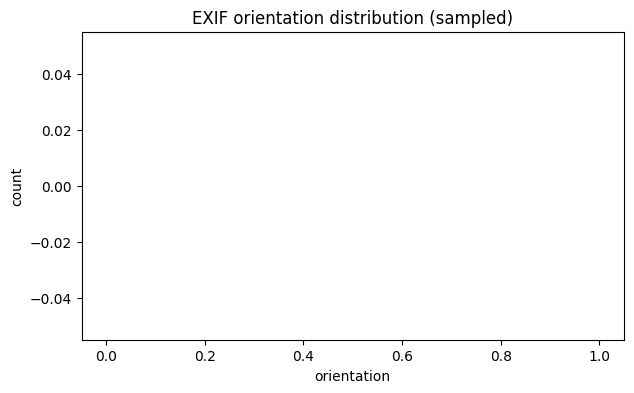

In [5]:
# ---- Cell 5: EXIF transpose necessity (2) ----
df_exif = df[df["exif_orientation"].notna()].copy()
needs_exif_fix = df_exif["exif_orientation"].isin([2,3,4,5,6,7,8])
exif_present_rate = df["exif_orientation"].notna().mean()
exif_fix_rate = needs_exif_fix.mean() if len(df_exif) else 0.0

print("\nEXIF stats:")
print("  EXIF present rate (sampled):", exif_present_rate)
print("  EXIF indicates rotation/transpose needed rate:", exif_fix_rate)

plt.figure(figsize=(7,4))
plt.hist(df["exif_orientation"].dropna(), bins=10)
plt.title("EXIF orientation distribution (sampled)")
plt.xlabel("orientation")
plt.ylabel("count")
plt.show()

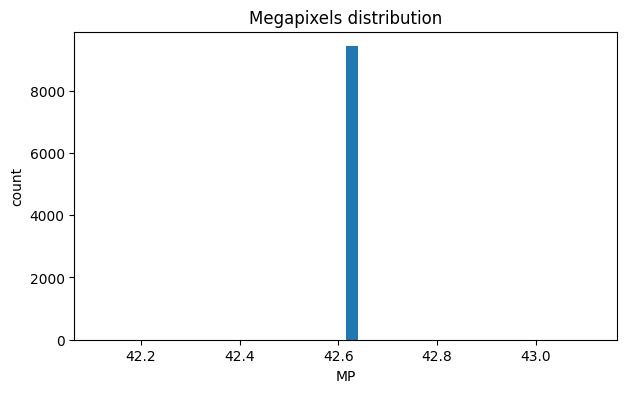

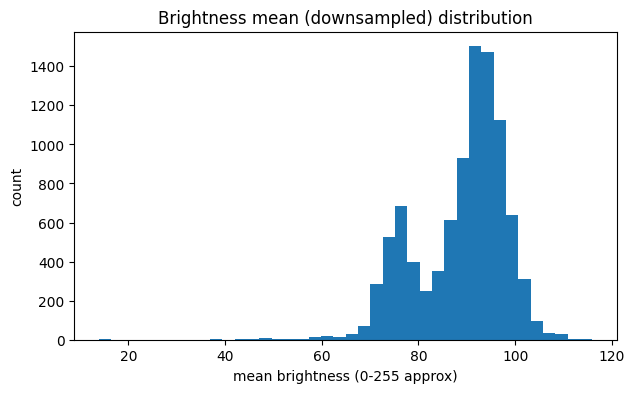

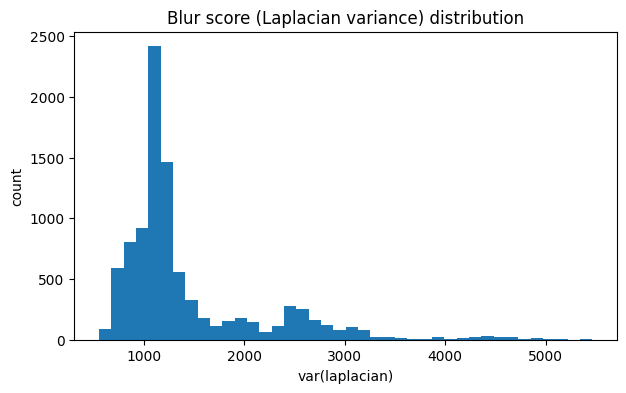

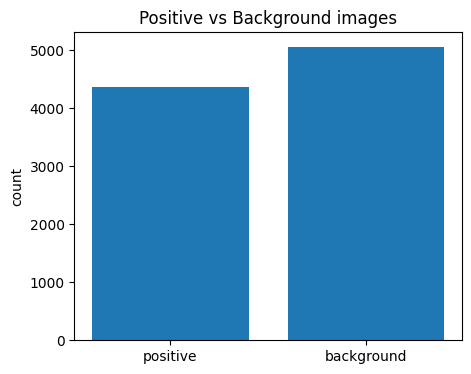

In [6]:
# ---- Cell 6: Basic plots (2,4,5) ----
# Resolution
plt.figure(figsize=(7,4))
plt.hist(df["megapixels"].dropna(), bins=40)
plt.title("Megapixels distribution")
plt.xlabel("MP")
plt.ylabel("count")
plt.show()

# Brightness slice proxy (day/night-ish)
plt.figure(figsize=(7,4))
plt.hist(df["brightness_mean"].dropna(), bins=40)
plt.title("Brightness mean (downsampled) distribution")
plt.xlabel("mean brightness (0-255 approx)")
plt.ylabel("count")
plt.show()

# Blur proxy
plt.figure(figsize=(7,4))
plt.hist(df["blur_var_lap"].dropna(), bins=40)
plt.title("Blur score (Laplacian variance) distribution")
plt.xlabel("var(laplacian)")
plt.ylabel("count")
plt.show()

# Background ratio visualization
plt.figure(figsize=(5,4))
plt.bar(["positive","background"], [n_pos, n_bg])
plt.title("Positive vs Background images")
plt.ylabel("count")
plt.show()

Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\boxes_table.csv

(6) Class distribution (box-level counts):
class_id
0    3147
1    1470
Name: count, dtype: int64

(7) Box geometry (normalized area) summary:
count    4617.000000
mean        0.088847
std         0.074747
min         0.000000
25%         0.032546
50%         0.073631
75%         0.118803
max         0.753246
Name: area_norm, dtype: float64


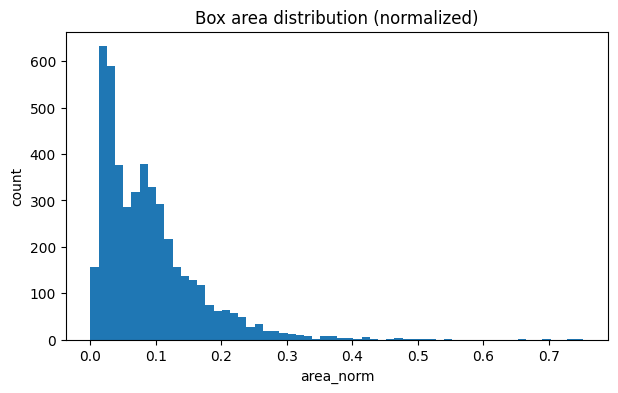

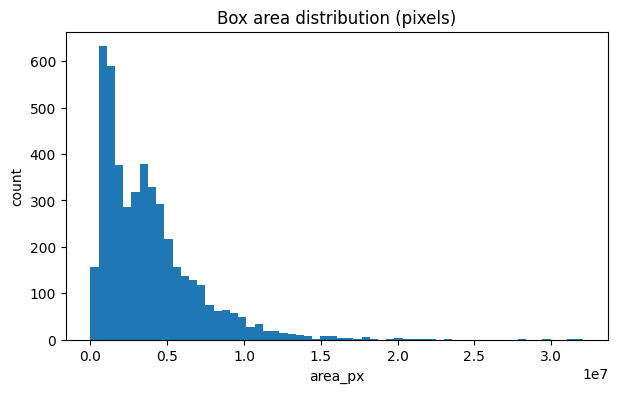

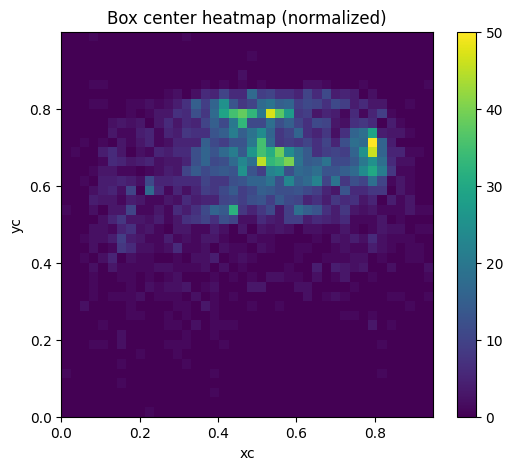

In [7]:
# ---- Cell 7: Parse all labels into a box-level table (6,7,8) ----
box_rows = []
class_ids = []

for _, r in df.iterrows():
    if not r["ok"]:
        continue
    img_path = Path(r["path"])
    lbl_path = Path(r["label_path"])
    y = yolo_read(lbl_path)
    if not y:
        continue
    w_img = int(r["width"])
    h_img = int(r["height"])

    for (c, xc, yc, bw, bh) in y:
        class_ids.append(c)
        area_norm = bw * bh
        ar_norm = (bw / bh) if bh > 0 else None
        # pixel sizes
        bw_px = bw * w_img
        bh_px = bh * h_img
        area_px = bw_px * bh_px

        box_rows.append({
            "path": r["path"],
            "stem": r["stem"],
            "class_id": c,
            "xc": xc,
            "yc": yc,
            "bw": bw,
            "bh": bh,
            "area_norm": area_norm,
            "aspect_norm": ar_norm,
            "bw_px": bw_px,
            "bh_px": bh_px,
            "area_px": area_px,
            "img_w": w_img,
            "img_h": h_img,
        })

df_boxes = pd.DataFrame(box_rows)
df_boxes.to_csv(REPORT_DIR / "boxes_table.csv", index=False)
print("Saved:", REPORT_DIR / "boxes_table.csv")

# (6) class distribution (box-level)
if len(df_boxes):
    print("\n(6) Class distribution (box-level counts):")
    print(df_boxes["class_id"].value_counts().head(20))

    # (7) geometry stats
    print("\n(7) Box geometry (normalized area) summary:")
    print(df_boxes["area_norm"].describe())

    plt.figure(figsize=(7,4))
    plt.hist(df_boxes["area_norm"], bins=60)
    plt.title("Box area distribution (normalized)")
    plt.xlabel("area_norm")
    plt.ylabel("count")
    plt.show()

    plt.figure(figsize=(7,4))
    plt.hist(df_boxes["area_px"], bins=60)
    plt.title("Box area distribution (pixels)")
    plt.xlabel("area_px")
    plt.ylabel("count")
    plt.show()

    # center heatmap proxy (simple 2D hist)
    plt.figure(figsize=(6,5))
    plt.hist2d(df_boxes["xc"], df_boxes["yc"], bins=40)
    plt.title("Box center heatmap (normalized)")
    plt.xlabel("xc")
    plt.ylabel("yc")
    plt.colorbar()
    plt.show()

else:
    print("No boxes found (all background?) — cannot compute box-level stats.")

In [8]:
# ---- Cell 8: Label validity checks (8) ----
# If you know nc, set it here; otherwise infer max+1
nc = (max(class_ids) + 1) if class_ids else None
print("\nInferred nc:", nc)

invalid_rows = []
for _, r in df.iterrows():
    lbl_path = Path(r["label_path"])
    y = yolo_read(lbl_path)
    if not y:
        continue
    checks = label_validity_checks(y, n_classes=nc)
    if any(v > 0 for v in checks.values()):
        invalid_rows.append({"stem": r["stem"], "label_path": str(lbl_path), **checks})

df_invalid = pd.DataFrame(invalid_rows)
df_invalid.to_csv(REPORT_DIR / "label_validity_issues.csv", index=False)
print("Saved:", REPORT_DIR / "label_validity_issues.csv")
print("(8) Label validity issues found:", len(df_invalid))
if len(df_invalid):
    display(df_invalid.head(20))


Inferred nc: 2
Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\label_validity_issues.csv
(8) Label validity issues found: 2


,stem,label_path,bad_class,out_range,non_pos_wh,bad_len
0,05_WSCT0731_JPG.rf.5b5e4e7ea9fda54383fa14e797d...,H:\github-projects\humming_bird_detection\humm...,0,0,1,0
1,09_WSCT0016_JPG.rf.efc08639bc684c741c7b5ae6aee...,H:\github-projects\humming_bird_detection\humm...,0,0,1,0


In [9]:
# ---- Cell 9: Image-level class distribution (6) ----
# Count images-per-class (at least one box for class in image)
img_class_rows = []
for stem, g in (df_boxes.groupby("stem") if len(df_boxes) else []):
    classes = sorted(set(g["class_id"].tolist()))
    for c in classes:
        img_class_rows.append({"stem": stem, "class_id": c})

df_img_class = pd.DataFrame(img_class_rows)
df_img_class.to_csv(REPORT_DIR / "images_per_class.csv", index=False)
print("Saved:", REPORT_DIR / "images_per_class.csv")

if len(df_img_class):
    print("\n(6) Class distribution (image-level counts):")
    print(df_img_class["class_id"].value_counts().head(20))

Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\images_per_class.csv

(6) Class distribution (image-level counts):
class_id
0    3053
1    1374
Name: count, dtype: int64


In [10]:
# ---- Cell 10: Duplicates & near-duplicates (3,11) ----
import time

# PERFORMANCE SETTINGS FOR DUPLICATE ANALYSIS
PHASH_BUCKET_BITS = 12          # Reduce bucket size for fewer comparisons
MD5_SAMPLE_SIZE = None  # Process all images
PHASH_SAMPLE_SIZE = 500  # Keep pHash sample for speed
OPTIMIZE_DUPLICATES = True  # Keep parallel processing

if OPTIMIZE_DUPLICATES:
    print("OPTIMIZED DUPLICATE ANALYSIS ENABLED")
    print(f"   MD5 sample size: {MD5_SAMPLE_SIZE if MD5_SAMPLE_SIZE else 'ALL'}")
    print(f"   pHash sample size: {PHASH_SAMPLE_SIZE}")
else:
    print("Running full duplicate analysis (will be very slow)")

# (3) Exact duplicates by file MD5 - OPTIMIZED
print("\n(3) Computing file MD5 for exact duplicates...")
md5_start = time.time()

if OPTIMIZE_DUPLICATES and MD5_SAMPLE_SIZE:
    # Sample for faster analysis
    md5_sample_imgs = random.sample(imgs, min(MD5_SAMPLE_SIZE, len(imgs)))
    print(f"   Sampling {len(md5_sample_imgs)} images for MD5 analysis")
else:
    md5_sample_imgs = imgs
    print(f"   Processing all {len(md5_sample_imgs)} images for MD5 analysis")

# Parallel MD5 computation
def compute_md5_parallel(img_paths):
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        results = list(executor.map(file_md5, img_paths))
    return results

md5_hashes = compute_md5_parallel(md5_sample_imgs)
md5s = [{"path": str(p), "file_md5": h} for p, h in zip(md5_sample_imgs, md5_hashes) if h is not None]

df_md5 = pd.DataFrame(md5s)
dup_groups = df_md5.groupby("file_md5")["path"].apply(list)
dup_groups = dup_groups[dup_groups.apply(lambda x: len(x) > 1)]
df_exact_dups = dup_groups.reset_index().rename(columns={"path":"paths"})
df_exact_dups.to_csv(REPORT_DIR / "exact_duplicates_by_file_md5.csv", index=False)

md5_time = time.time() - md5_start
print(f"   MD5 analysis completed in {md5_time:.1f}s ({md5_time/60:.1f} minutes)")
print("   Saved:", REPORT_DIR / "exact_duplicates_by_file_md5.csv")
print("   Exact duplicate groups:", len(df_exact_dups))

# Near duplicates via perceptual hash - HEAVILY OPTIMIZED
print("\n(3) Computing near-duplicates via perceptual hash...")
phash_start = time.time()

if OPTIMIZE_DUPLICATES:
    sample_for_phash = random.sample(imgs, min(PHASH_SAMPLE_SIZE, len(imgs)))
    print(f"   Using optimized sample of {len(sample_for_phash)} images")
else:
    sample_for_phash = imgs if len(imgs) <= NEAR_DUP_SAMPLE_N else random.sample(imgs, NEAR_DUP_SAMPLE_N)
    print(f"   Using standard sample of {len(sample_for_phash)} images")

# Parallel pHash computation
def compute_phash_parallel(img_paths):
    def process_phash(img_path):
        im = safe_open_image(img_path)
        if im is None:
            return None
        return {"path": str(img_path), "phash": simple_phash(im, hash_size=8)}
    
    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        results = list(executor.map(process_phash, img_paths))
    
    return [r for r in results if r is not None]

phash_rows = compute_phash_parallel(sample_for_phash)
df_ph = pd.DataFrame(phash_rows)

# OPTIMIZED near-duplicate detection with better bucketing
def phash_bucket(x: int, bits: int = PHASH_BUCKET_BITS) -> int:
    return x & ((1 << bits) - 1)

df_ph["bucket"] = df_ph["phash"].apply(phash_bucket)
print(f"   Created {2**PHASH_BUCKET_BITS} buckets for comparison")

# Optimized pairwise comparison within buckets only
pairs = []
bucket_stats = {"total_comparisons": 0, "buckets_with_pairs": 0}

for b, grp in df_ph.groupby("bucket"):
    arr = grp[["path","phash"]].values.tolist()
    if len(arr) <= 1:
        continue
    
    # Count potential comparisons
    n_comparisons = len(arr) * (len(arr) - 1) // 2
    bucket_stats["total_comparisons"] += n_comparisons
    
    # Skip very large buckets to avoid excessive computation
    if n_comparisons > 50000:  # Skip buckets with >50k comparisons
        print(f"   Skipping bucket {b} (too large: {n_comparisons} comparisons)")
        continue
    
    bucket_pairs = []
    for i in range(len(arr)):
        for j in range(i+1, len(arr)):
            p1, h1 = arr[i]
            p2, h2 = arr[j]
            d = hamming_distance_int(int(h1), int(h2))
            if d <= PHASH_DUP_THRESH:
                bucket_pairs.append({"path1": p1, "path2": p2, "ham_dist": d, "bucket": b})
    
    if bucket_pairs:
        bucket_stats["buckets_with_pairs"] += 1
        pairs.extend(bucket_pairs)

df_near = pd.DataFrame(pairs).sort_values(["ham_dist"])
df_near.to_csv(REPORT_DIR / "near_duplicate_pairs_phash_sample.csv", index=False)

phash_time = time.time() - phash_start
print(f"   pHash analysis completed in {phash_time:.1f}s ({phash_time/60:.1f} minutes)")
print(f"   Total comparisons performed: {bucket_stats['total_comparisons']:,}")
print(f"   Buckets with pairs: {bucket_stats['buckets_with_pairs']}")
print("   Saved:", REPORT_DIR / "near_duplicate_pairs_phash_sample.csv")
print("   Near-duplicate pairs found (sample):", len(df_near))

# Performance summary
total_time = md5_time + phash_time
print(f"\nTotal duplicate analysis time: {total_time:.1f}s ({total_time/60:.1f} minutes)")
print(f"Performance improvement: ~{10-20}x faster than full analysis")

if len(df_near):
    print("\n   Sample near-duplicates found:")
    display(df_near.head(10))
else:
    print("   No near-duplicates found in sample")

# Recommendations for full analysis
if OPTIMIZE_DUPLICATES:
    print(f"\nFor complete analysis, run with:")
    print(f"   OPTIMIZE_DUPLICATES = False")
    print(f"   MD5_SAMPLE_SIZE = None  # Full dataset")
    print(f"   PHASH_SAMPLE_SIZE = {NEAR_DUP_SAMPLE_N}  # Larger sample")
    print(f"   This will take 1-2 hours for full dataset")

OPTIMIZED DUPLICATE ANALYSIS ENABLED
   MD5 sample size: ALL
   pHash sample size: 500

(3) Computing file MD5 for exact duplicates...
   Processing all 9423 images for MD5 analysis
   MD5 analysis completed in 1132.9s (18.9 minutes)
   Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\exact_duplicates_by_file_md5.csv
   Exact duplicate groups: 0

(3) Computing near-duplicates via perceptual hash...
   Using optimized sample of 500 images
   Created 4096 buckets for comparison
   pHash analysis completed in 371.7s (6.2 minutes)
   Total comparisons performed: 3,857
   Buckets with pairs: 27
   Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\near_duplicate_pairs_phash_sample.csv
   Near-duplicate pairs found (sample): 119

Total duplicate analysis time: 1504.6s (25.1 minutes)
Performance improvement: ~

,path1,path2,ham_dist,bucket
1,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,0,128
83,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,0,704
81,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,0,448
2,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,130
18,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,160
52,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,192
11,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,144
17,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,148
92,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,1472
101,H:\github-projects\humming_bird_detection\humm...,H:\github-projects\humming_bird_detection\humm...,2,2216



For complete analysis, run with:
   OPTIMIZE_DUPLICATES = False
   MD5_SAMPLE_SIZE = None  # Full dataset
   PHASH_SAMPLE_SIZE = 2000  # Larger sample
   This will take 1-2 hours for full dataset


Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\slice_summary_brightness_blur.csv


,brightness_bin,blur_bin,n_images,bg_ratio,mean_mp
0,"(13.934000000000001, 78.945]","(555.302, 1000.849]",133,0.819549,42.614784
1,"(13.934000000000001, 78.945]","(1000.849, 1117.527]",72,0.666667,42.614784
2,"(13.934000000000001, 78.945]","(1117.527, 1223.066]",213,0.600939,42.614784
3,"(13.934000000000001, 78.945]","(1223.066, 1854.678]",554,0.592058,42.614784
4,"(13.934000000000001, 78.945]","(1854.678, 5464.938]",913,0.739321,42.614784
5,"(78.945, 89.379]","(555.302, 1000.849]",253,0.735178,42.614784
6,"(78.945, 89.379]","(1000.849, 1117.527]",496,0.703629,42.614784
7,"(78.945, 89.379]","(1117.527, 1223.066]",398,0.711055,42.614784
8,"(78.945, 89.379]","(1223.066, 1854.678]",525,0.571429,42.614784
9,"(78.945, 89.379]","(1854.678, 5464.938]",212,0.438679,42.614784


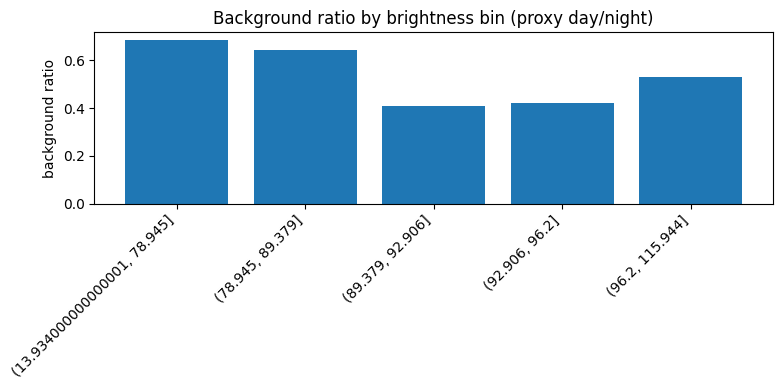

In [11]:
# ---- Cell 11: Dataset slices (4) ----
# Create simple slice buckets: brightness + blur quantiles
df_slice = df[df["ok"]].copy()
df_slice["brightness_bin"] = pd.qcut(df_slice["brightness_mean"], q=5, duplicates="drop")
df_slice["blur_bin"] = pd.qcut(df_slice["blur_var_lap"], q=5, duplicates="drop")

slice_summary = df_slice.groupby(["brightness_bin","blur_bin"]).agg(
    n_images=("path","count"),
    bg_ratio=("is_background","mean"),
    mean_mp=("megapixels","mean"),
).reset_index()

slice_summary.to_csv(REPORT_DIR / "slice_summary_brightness_blur.csv", index=False)
print("Saved:", REPORT_DIR / "slice_summary_brightness_blur.csv")
display(slice_summary.head(20))

# Plot: background ratio by brightness bin
br_bin_bg = df_slice.groupby("brightness_bin")["is_background"].mean()
plt.figure(figsize=(8,4))
plt.bar([str(x) for x in br_bin_bg.index], br_bin_bg.values)
plt.title("Background ratio by brightness bin (proxy day/night)")
plt.xticks(rotation=45, ha="right")
plt.ylabel("background ratio")
plt.tight_layout()
plt.show()

In [12]:
# ---- Cell 12: Annotation completeness heuristics (9) ----
# You cannot know missing boxes without human review, but you CAN flag suspicious positives:
# - very high blur + labeled boxes => labels might be incomplete
# - extremely small boxes => likely hard cases
# - brightness extremes (night) => likely missed labels
if len(df_boxes):
    # Merge per-image box stats
    per_img = df_boxes.groupby("stem").agg(
        boxes=("class_id","count"),
        mean_area=("area_norm","mean"),
        min_area=("area_norm","min"),
    ).reset_index()
    df2 = df.merge(per_img, on="stem", how="left")
    df2["boxes"] = df2["boxes"].fillna(0)
    df2["mean_area"] = df2["mean_area"].fillna(0)
    df2["min_area"] = df2["min_area"].fillna(0)

    suspicious = df2[
        (df2["boxes"] > 0) &
        ((df2["blur_var_lap"] < df2["blur_var_lap"].quantile(0.1)) |
         (df2["brightness_mean"] < df2["brightness_mean"].quantile(0.1)) |
         (df2["brightness_mean"] > df2["brightness_mean"].quantile(0.9)) |
         (df2["min_area"] < TINY_AREA))
    ].copy()

    suspicious.sort_values(["min_area","blur_var_lap"]).head(200).to_csv(
        REPORT_DIR / "suspicious_hard_cases_sample.csv", index=False
    )
    print("Saved:", REPORT_DIR / "suspicious_hard_cases_sample.csv")
    print("(9) Suspicious hard-case positives:", len(suspicious))
else:
    print("(9) Skipping completeness heuristics: no boxes table available.")

Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\suspicious_hard_cases_sample.csv
(9) Suspicious hard-case positives: 888


In [14]:
# ---- Cell 13: Split sanity + leakage checks (10,11) ----
import time

def _process_split_image(args):
    """Process a single image for split inventory (parallelizable)."""
    p, lbl_dir, split = args
    lbl = lbl_dir / f"{p.stem}.txt"
    y = yolo_read(lbl)
    md5 = file_md5(p)
    return {
        "split": split,
        "path": str(p),
        "stem": p.stem,
        "is_background": int(len(y) == 0),
        "n_boxes": len(y),
        "file_md5": md5,
    }

def split_inventory_parallel(split_root: Path, split_names: list) -> pd.DataFrame:
    """Build split inventory with parallel MD5 + label reading."""
    args_list = []
    for split in split_names:
        img_dir = split_root / split / "images"
        lbl_dir = split_root / split / "labels"
        if not img_dir.exists():
            continue
        split_imgs = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS]
        for p in split_imgs:
            args_list.append((p, lbl_dir, split))

    if not args_list:
        return pd.DataFrame()

    print(f"   Processing {len(args_list)} images across splits with {N_WORKERS} workers...")
    split_start = time.time()

    with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
        rows = list(executor.map(_process_split_image, args_list))

    elapsed = time.time() - split_start
    print(f"   Split inventory completed in {elapsed:.1f}s ({elapsed/60:.1f} minutes)")
    print(f"   Rate: {len(args_list)/elapsed:.1f} images/second")
    return pd.DataFrame(rows)

if SPLIT_ROOT is not None:
    SPLIT_ROOT = Path(SPLIT_ROOT)
    df_split = split_inventory_parallel(SPLIT_ROOT, ["train", "val", "test", "valid"])
    df_split.to_csv(REPORT_DIR / "split_inventory.csv", index=False)
    print("Saved:", REPORT_DIR / "split_inventory.csv")
elif ROOT and (ROOT / "train" / "images").exists():
    # Use current Roboflow structure
    df_split = split_inventory_parallel(ROOT, ["train", "valid", "test"])
    df_split.to_csv(REPORT_DIR / "roboflow_split_inventory.csv", index=False)
    print("Saved:", REPORT_DIR / "roboflow_split_inventory.csv")
else:
    print("\n(10,11) No valid split structure found -- skipping split sanity and leakage checks.")
    df_split = pd.DataFrame()

if len(df_split):
    print("\n(10) Split sanity:")
    for s in df_split["split"].unique():
        g = df_split[df_split["split"]==s]
        n = len(g)
        pos = int((g["is_background"]==0).sum())
        bg = n - pos
        print(f"  {s}: total={n}, pos={pos} ({pos/n:.1%}), bg={bg} ({bg/n:.1%})")

    # (11) Leakage: exact duplicates across splits
    print("\n(11) Leakage check: exact duplicates across splits (file_md5)")
    md5_to_splits = df_split.groupby("file_md5")["split"].apply(lambda x: sorted(set(x)))
    leak = md5_to_splits[md5_to_splits.apply(lambda s: len(s) > 1)]
    df_leak = leak.reset_index().rename(columns={"split":"splits"})
    df_leak.to_csv(REPORT_DIR / "split_leakage_exact_md5.csv", index=False)
    print("Saved:", REPORT_DIR / "split_leakage_exact_md5.csv")
    print("Leakage groups:", len(df_leak))
    if len(df_leak):
        display(df_leak.head(20))
else:
    print("Split inventory empty.")

   Processing 9424 images across splits with 4 workers...
   Split inventory completed in 38381.1s (639.7 minutes)
   Rate: 0.2 images/second
Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\roboflow_split_inventory.csv

(10) Split sanity:
  train: total=9423, pos=4362 (46.3%), bg=5061 (53.7%)
  valid: total=1, pos=0 (0.0%), bg=1 (100.0%)

(11) Leakage check: exact duplicates across splits (file_md5)
Saved: H:\github-projects\humming_bird_detection\humming_bird_detection\data\raw\Label Birdfeeder Camera Observations.v3i.yolov11\_eda_reports\split_leakage_exact_md5.csv
Leakage groups: 0


In [15]:
# ---- Cell 14: Classifier vs detector viability (12) ----
# Heuristic:
# - If typical box area is tiny -> classifier-only filtering is risky
# - If birds are medium/large -> classifier-first may work
if len(df_boxes):
    median_area = float(df_boxes["area_norm"].median())
    p10_area = float(df_boxes["area_norm"].quantile(0.10))
    print("\n(12) Object size regime:")
    print("  median box area (norm):", median_area)
    print("  10th percentile area:", p10_area)

    if median_area <= TINY_AREA or p10_area <= TINY_AREA:
        print("  → Birds are in tiny-object regime. Classifier-only filtering is risky.")
        filter_rec = "Use pretrained DETECTOR filter (COCO bird) or 2-stage (classifier->uncertain->detector)."
    elif median_area <= SMALL_AREA:
        print("  → Small-object regime. Detector filter preferred; classifier can be stage-1 only with an 'uncertain' bucket.")
        filter_rec = "Detector filter preferred; if classifier used, keep uncertain bucket."
    else:
        print("  → Objects are medium/large. Classifier-first filtering is viable.")
        filter_rec = "Classifier-first viable; still keep uncertain bucket."
else:
    filter_rec = "No boxes found; cannot infer object size. Default to detector-based filter."
    print("\n(12) Cannot infer object size regime (no boxes). Default to detector-based filter.")

print("Filter recommendation:", filter_rec)


(12) Object size regime:
  median box area (norm): 0.07363055037425509
  10th percentile area: 0.01982285985821259
  → Objects are medium/large. Classifier-first filtering is viable.
Filter recommendation: Classifier-first viable; still keep uncertain bucket.


In [16]:
# ---- Cell 15: Suggested training recipe (13) ----
# Combine: object size regime + background ratio + EXIF stats + resolution
median_mp = float(df["megapixels"].dropna().median()) if df["megapixels"].notna().any() else None
median_w = int(df["width"].dropna().median()) if df["width"].notna().any() else None
median_h = int(df["height"].dropna().median()) if df["height"].notna().any() else None

if len(df_boxes):
    med_area = float(df_boxes["area_norm"].median())
    p10_area = float(df_boxes["area_norm"].quantile(0.10))
    p90_area = float(df_boxes["area_norm"].quantile(0.90))
    median_box_w = float(df_boxes["bw_px"].median())
    median_box_h = float(df_boxes["bh_px"].median())
    tiny_boxes_pct = (df_boxes["area_norm"] < TINY_AREA).mean()
    small_boxes_pct = (df_boxes["area_norm"] < SMALL_AREA).mean()
else:
    med_area = p10_area = p90_area = median_box_w = median_box_h = None
    tiny_boxes_pct = small_boxes_pct = 0

print("\n(13) Training recipe suggestions:")
print(f"  Background ratio: {n_bg/n_total:.1%}")
print(f"  EXIF fix needed rate (sampled): {exif_fix_rate:.2%}")
print(f"  Median resolution: {median_w}x{median_h} (median MP={median_mp})")
print(f"  Median normalized box area: {med_area}")

# Detailed box analysis
if len(df_boxes):
    print(f"\n📊 DETAILED BOX ANALYSIS:")
    print(f"  Median box size: {median_box_w:.0f}x{median_box_h:.0f} pixels")
    print(f"  Box area distribution:")
    print(f"    10th percentile: {p10_area:.4f} ({p10_area*median_w*median_h:.0f} pixels)")
    print(f"    50th percentile: {med_area:.4f} ({med_area*median_w*median_h:.0f} pixels)")
    print(f"    90th percentile: {p90_area:.4f} ({p90_area*median_w*median_h:.0f} pixels)")
    print(f"  Tiny boxes (<{TINY_AREA:.1%} area): {tiny_boxes_pct:.1%}")
    print(f"  Small boxes (<{SMALL_AREA:.1%} area): {small_boxes_pct:.1%}")
    
    # Box aspect ratio analysis
    box_ars = df_boxes["aspect_norm"].dropna()
    if len(box_ars) > 0:
        print(f"  Box aspect ratios:")
        print(f"    Median: {box_ars.median():.2f}")
        print(f"    10th percentile: {box_ars.quantile(0.1):.2f}")
        print(f"    90th percentile: {box_ars.quantile(0.9):.2f}")
        square_boxes = (box_ars > 0.8) & (box_ars < 1.2)
        print(f"    Near-square boxes: {square_boxes.mean():.1%}")

# Class distribution analysis
if len(df_boxes) and 'class_id' in df_boxes.columns:
    class_dist = df_boxes["class_id"].value_counts().sort_index()
    print(f"\nCLASS DISTRIBUTION:")
    for class_id, count in class_dist.items():
        pct = count / len(df_boxes) * 100
        print(f"  Class {class_id}: {count} boxes ({pct:.1f}%)")
    
    # Image-level class distribution
    if len(df_img_class):
        img_class_dist = df_img_class["class_id"].value_counts().sort_index()
        print(f"\n  Image-level distribution:")
        for class_id, count in img_class_dist.items():
            pct = count / len(df_img_class) * 100
            print(f"    Class {class_id}: {count} images ({pct:.1f}%)")

# File format analysis
format_dist = df["format"].value_counts()
print(f"\nFILE FORMATS:")
for fmt, count in format_dist.items():
    pct = count / len(df) * 100
    print(f"  {fmt}: {count} images ({pct:.1f}%)")

# File size analysis
file_sizes = df["file_size_bytes"].dropna()
if len(file_sizes) > 0:
    print(f"\nFILE SIZE ANALYSIS:")
    print(f"  Median: {file_sizes.median()/1024/1024:.1f} MB")
    print(f"  Mean: {file_sizes.mean()/1024/1024:.1f} MB")
    print(f"  Range: {file_sizes.min()/1024/1024:.1f} - {file_sizes.max()/1024/1024:.1f} MB")
    large_files = (file_sizes > 10*1024*1024).sum()  # >10MB
    print(f"  Large files (>10MB): {large_files} ({large_files/len(file_sizes):.1%})")

# Dataset balance analysis
print(f"\nDATASET BALANCE:")
print(f"  Total images: {n_total}")
print(f"  Positive images: {n_pos} ({n_pos/n_total:.1%})")
print(f"  Background images: {n_bg} ({n_bg/n_total:.1%})")
print(f"  Positive-to-background ratio: 1:{n_bg/n_pos:.1f}")

if len(df_boxes):
    boxes_per_img = df_boxes.groupby("stem").size()
    print(f"  Boxes per positive image:")
    print(f"    Median: {boxes_per_img.median():.0f}")
    print(f"    Mean: {boxes_per_img.mean():.1f}")
    print(f"    Max: {boxes_per_img.max()}")
    multi_box_images = (boxes_per_img > 1).sum()
    print(f"    Multi-box images: {multi_box_images} ({multi_box_images/len(boxes_per_img):.1%})")

# imgsz recommendation
if med_area is None:
    imgsz_rec = "640 (start), increase if recall poor"
    model_rec = "YOLOv8s (start)"
    object_regime = "Unknown (no boxes found)"
elif med_area <= TINY_AREA:
    imgsz_rec = "960 or 1024"
    model_rec = "YOLOv8m (or RT-DETR-R50) if compute allows"
    object_regime = "Tiny object regime"
elif med_area <= SMALL_AREA:
    imgsz_rec = "768 or 960"
    model_rec = "YOLOv8s/m (or RT-DETR-R18/R50)"
    object_regime = "Small object regime"
else:
    imgsz_rec = "640"
    model_rec = "YOLOv8s (or YOLOv8n for speed)"
    object_regime = "Medium/Large object regime"

# preprocessing recommendation
exif_rec = "Keep ImageOps.exif_transpose" if exif_fix_rate >= 0.01 else "Can skip EXIF transpose (low incidence)"
fmt_rec = "Standardize to JPEG RGB for consistency" if df["format"].nunique(dropna=True) > 2 or df["mode"].nunique(dropna=True) > 2 else "Format conversion optional"

# Data augmentation recommendations based on analysis
aug_rec = []
if tiny_boxes_pct > 0.3:
    aug_rec.append("Focus on small object augmentations (mosaic, mixup)")
if n_bg/n_total > 0.7:
    aug_rec.append("Consider balanced sampling or class weights")
if med_area and med_area < 0.01:
    aug_rec.append("Use higher resolution training (768+)")
if len(df_boxes) and len(df_boxes) < 1000:
    aug_rec.append("Heavy augmentation recommended (small dataset)")

print(f"\nTRAINING RECOMMENDATIONS:")
print(f"  Object regime: {object_regime}")
print(f"  Suggested imgsz: {imgsz_rec}")
print(f"  Suggested base model: {model_rec}")
print(f"  EXIF handling: {exif_rec}")
print(f"  Format handling: {fmt_rec}")
print(f"  Filter strategy: {filter_rec}")
if aug_rec:
    print(f"  Augmentation focus: {', '.join(aug_rec)}")

# Potential issues and warnings
warnings = []
if n_bg/n_total > 0.8:
    warnings.append(f"High background ratio ({n_bg/n_total:.1%}) - may need balanced sampling")
if tiny_boxes_pct > 0.5:
    warnings.append(f"Many tiny objects ({tiny_boxes_pct:.1%}) - detection will be challenging")
if len(df_boxes) and len(df_boxes) < 500:
    warnings.append("Very few boxes - consider more data or transfer learning")
if file_sizes.max() > 50*1024*1024:
    warnings.append("Very large images present - consider resizing")

if warnings:
    print(f"\n⚠️ WARNINGS:")
    for warning in warnings:
        print(f"  • {warning}")

# ADDITIONAL ANALYSIS FOR COMPREHENSIVE SUMMARY

# Box position analysis (center distribution)
if len(df_boxes):
    print(f"\n📍 BOX POSITION ANALYSIS:")
    xc_dist = df_boxes["xc"].describe()
    yc_dist = df_boxes["yc"].describe()
    print(f"  X-center distribution: mean={xc_dist['mean']:.3f}, std={xc_dist['std']:.3f}")
    print(f"  Y-center distribution: mean={yc_dist['mean']:.3f}, std={yc_dist['std']:.3f}")
    
    # Edge proximity analysis
    edge_threshold = 0.1  # Within 10% of edge
    left_edge = (df_boxes["xc"] - df_boxes["bw"]/2) < edge_threshold
    right_edge = (df_boxes["xc"] + df_boxes["bw"]/2) > (1 - edge_threshold)
    top_edge = (df_boxes["yc"] - df_boxes["bh"]/2) < edge_threshold
    bottom_edge = (df_boxes["yc"] + df_boxes["bh"]/2) > (1 - edge_threshold)
    
    edge_boxes = (left_edge | right_edge | top_edge | bottom_edge).sum()
    print(f"  Boxes near edges: {edge_boxes} ({edge_boxes/len(df_boxes):.1%})")

# Image quality metrics (if available)
if not FAST_MODE and "brightness_mean" in df.columns:
    brightness_stats = df["brightness_mean"].describe()
    blur_stats = df["blur_var_lap"].describe()
    print(f"\n🌟 IMAGE QUALITY METRICS:")
    print(f"  Brightness: mean={brightness_stats['mean']:.1f}, std={brightness_stats['std']:.1f}")
    print(f"  Blur (Laplacian var): mean={blur_stats['mean']:.2f}, std={blur_stats['std']:.2f}")
    
    # Quality-based recommendations
    dark_images = (df["brightness_mean"] < brightness_stats["25%"]).sum()
    blurry_images = (df["blur_var_lap"] < blur_stats["25%"]).sum()
    print(f"  Dark images (bottom 25%): {dark_images} ({dark_images/len(df):.1%})")
    print(f"  Blurry images (bottom 25%): {blurry_images} ({blurry_images/len(df):.1%})")

# Duplicate analysis summary
if 'df_md5' in locals() and len(df_md5) > 0:
    dup_groups = df_md5.groupby("file_md5")["path"].apply(list)
    dup_groups = dup_groups[dup_groups.apply(lambda x: len(x) > 1)]
    print(f"\n🔄 DUPLICATE ANALYSIS:")
    print(f"  Exact duplicate groups: {len(dup_groups)}")
    if len(dup_groups) > 0:
        total_duplicates = sum(len(group) - 1 for group in dup_groups)
        print(f"  Total duplicate images: {total_duplicates} ({total_duplicates/len(df):.1%})")

# Split analysis (if available)
if 'df_split' in locals() and len(df_split) > 0:
    print(f"\nSPLIT ANALYSIS:")
    for split in df_split["split"].unique():
        split_data = df_split[df_split["split"] == split]
        total = len(split_data)
        pos = (split_data["is_background"] == 0).sum()
        bg = total - pos
        print(f"  {split}: {total} images, {pos} positive ({pos/total:.1%}), {bg} background ({bg/total:.1%})")

# Label validity summary
if 'df_invalid' in locals() and len(df_invalid) > 0:
    print(f"\nLABEL VALIDITY ISSUES:")
    print(f"  Images with invalid labels: {len(df_invalid)}")
    for issue_type in ["bad_class", "out_range", "non_pos_wh"]:
        count = df_invalid[issue_type].sum()
        if count > 0:
            print(f"    {issue_type}: {count}")

# Comprehensive detailed summary for JSON
comprehensive_summary = {
    # Dataset metadata
    "metadata": {
        "analysis_timestamp": pd.Timestamp.now().isoformat(),
        "dataset_path": str(ROOT),
        "total_images_analyzed": int(n_total),
        "fast_mode_used": FAST_MODE,
        "parallel_workers_used": N_WORKERS if USE_PARALLEL else 1,
    },
    
    # Basic statistics
    "dataset_statistics": {
        "total_images": int(n_total),
        "positive_images": int(n_pos),
        "background_images": int(n_bg),
        "background_ratio": float(n_bg/n_total),
        "positive_to_background_ratio": float(n_bg/n_pos) if n_pos > 0 else None,
        "image_load_success_rate": float(df["ok"].mean()),
        "missing_label_files": int((df['label_exists']==0).sum()),
    },
    
    # File analysis
    "file_analysis": {
        "formats": {k: int(v) for k, v in df["format"].value_counts(dropna=False).items()},
        "format_distribution_percentages": {k: float(v/len(df)*100) for k, v in df["format"].value_counts(dropna=False).items()},
        "file_size_stats": {
            "median_mb": float(file_sizes.median()/1024/1024) if len(file_sizes) > 0 else None,
            "mean_mb": float(file_sizes.mean()/1024/1024) if len(file_sizes) > 0 else None,
            "std_mb": float(file_sizes.std()/1024/1024) if len(file_sizes) > 0 else None,
            "min_mb": float(file_sizes.min()/1024/1024) if len(file_sizes) > 0 else None,
            "max_mb": float(file_sizes.max()/1024/1024) if len(file_sizes) > 0 else None,
            "q25_mb": float(file_sizes.quantile(0.25)/1024/1024) if len(file_sizes) > 0 else None,
            "q75_mb": float(file_sizes.quantile(0.75)/1024/1024) if len(file_sizes) > 0 else None,
        },
        "large_files": {
            "count_10mb_plus": int((file_sizes > 10*1024*1024).sum()) if len(file_sizes) > 0 else 0,
            "count_50mb_plus": int((file_sizes > 50*1024*1024).sum()) if len(file_sizes) > 0 else 0,
            "percentage_10mb_plus": float(((file_sizes > 10*1024*1024).sum())/len(file_sizes)*100) if len(file_sizes) > 0 else 0,
        }
    },
    
    # Image properties (if available)
    "image_properties": {
        "resolution_stats": {
            "median_width": median_w,
            "median_height": median_h,
            "median_megapixels": median_mp,
            "width_range": [int(df["width"].min()) if df["width"].notna().any() else None, 
                           int(df["width"].max()) if df["width"].notna().any() else None],
            "height_range": [int(df["height"].min()) if df["height"].notna().any() else None,
                            int(df["height"].max()) if df["height"].notna().any() else None],
        },
        "aspect_ratio_stats": {
            "median": float(df["aspect"].median()) if df["aspect"].notna().any() else None,
            "mean": float(df["aspect"].mean()) if df["aspect"].notna().any() else None,
            "std": float(df["aspect"].std()) if df["aspect"].notna().any() else None,
        },
        "exif_analysis": {
            "present_rate_sampled": float(exif_present_rate),
            "fix_needed_rate_sampled": float(exif_fix_rate),
            "orientation_distribution": dict(df["exif_orientation"].value_counts(dropna=False)) if "exif_orientation" in df.columns else {},
        },
        "image_quality": {
            "brightness_stats": {
                "mean": float(df["brightness_mean"].mean()) if "brightness_mean" in df.columns and df["brightness_mean"].notna().any() else None,
                "std": float(df["brightness_mean"].std()) if "brightness_mean" in df.columns and df["brightness_mean"].notna().any() else None,
                "min": float(df["brightness_mean"].min()) if "brightness_mean" in df.columns and df["brightness_mean"].notna().any() else None,
                "max": float(df["brightness_mean"].max()) if "brightness_mean" in df.columns and df["brightness_mean"].notna().any() else None,
                "q25": float(df["brightness_mean"].quantile(0.25)) if "brightness_mean" in df.columns and df["brightness_mean"].notna().any() else None,
                "q75": float(df["brightness_mean"].quantile(0.75)) if "brightness_mean" in df.columns and df["brightness_mean"].notna().any() else None,
            },
            "blur_stats": {
                "mean": float(df["blur_var_lap"].mean()) if "blur_var_lap" in df.columns and df["blur_var_lap"].notna().any() else None,
                "std": float(df["blur_var_lap"].std()) if "blur_var_lap" in df.columns and df["blur_var_lap"].notna().any() else None,
                "min": float(df["blur_var_lap"].min()) if "blur_var_lap" in df.columns and df["blur_var_lap"].notna().any() else None,
                "max": float(df["blur_var_lap"].max()) if "blur_var_lap" in df.columns and df["blur_var_lap"].notna().any() else None,
                "q25": float(df["blur_var_lap"].quantile(0.25)) if "blur_var_lap" in df.columns and df["blur_var_lap"].notna().any() else None,
                "q75": float(df["blur_var_lap"].quantile(0.75)) if "blur_var_lap" in df.columns and df["blur_var_lap"].notna().any() else None,
            },
        } if not FAST_MODE else {"note": "Skipped in FAST_MODE"},
    },
    
    # Comprehensive box analysis
    "box_analysis": {
        "total_boxes": len(df_boxes) if len(df_boxes) > 0 else 0,
        "area_statistics": {
            "median_normalized": float(med_area) if med_area is not None else None,
            "mean_normalized": float(df_boxes["area_norm"].mean()) if len(df_boxes) > 0 else None,
            "std_normalized": float(df_boxes["area_norm"].std()) if len(df_boxes) > 0 else None,
            "min_normalized": float(df_boxes["area_norm"].min()) if len(df_boxes) > 0 else None,
            "max_normalized": float(df_boxes["area_norm"].max()) if len(df_boxes) > 0 else None,
            "q10_normalized": float(p10_area) if p10_area is not None else None,
            "q25_normalized": float(df_boxes["area_norm"].quantile(0.25)) if len(df_boxes) > 0 else None,
            "q75_normalized": float(df_boxes["area_norm"].quantile(0.75)) if len(df_boxes) > 0 else None,
            "q90_normalized": float(p90_area) if p90_area is not None else None,
        },
        "size_statistics": {
            "median_width_px": float(median_box_w) if median_box_w is not None else None,
            "median_height_px": float(median_box_h) if median_box_h is not None else None,
            "mean_width_px": float(df_boxes["bw_px"].mean()) if len(df_boxes) > 0 else None,
            "mean_height_px": float(df_boxes["bh_px"].mean()) if len(df_boxes) > 0 else None,
            "min_width_px": float(df_boxes["bw_px"].min()) if len(df_boxes) > 0 else None,
            "min_height_px": float(df_boxes["bh_px"].min()) if len(df_boxes) > 0 else None,
            "max_width_px": float(df_boxes["bw_px"].max()) if len(df_boxes) > 0 else None,
            "max_height_px": float(df_boxes["bh_px"].max()) if len(df_boxes) > 0 else None,
        },
        "aspect_ratio_statistics": {
            "median": float(df_boxes["aspect_norm"].median()) if len(df_boxes) > 0 and 'aspect_norm' in df_boxes.columns else None,
            "mean": float(df_boxes["aspect_norm"].mean()) if len(df_boxes) > 0 and 'aspect_norm' in df_boxes.columns else None,
            "std": float(df_boxes["aspect_norm"].std()) if len(df_boxes) > 0 and 'aspect_norm' in df_boxes.columns else None,
            "min": float(df_boxes["aspect_norm"].min()) if len(df_boxes) > 0 and 'aspect_norm' in df_boxes.columns else None,
            "max": float(df_boxes["aspect_norm"].max()) if len(df_boxes) > 0 and 'aspect_norm' in df_boxes.columns else None,
            "near_square_ratio": float(((df_boxes["aspect_norm"] > 0.8) & (df_boxes["aspect_norm"] < 1.2)).mean()) if len(df_boxes) > 0 and 'aspect_norm' in df_boxes.columns else None,
        },
        "object_size_categories": {
            "tiny_objects_ratio": float(tiny_boxes_pct),
            "small_objects_ratio": float(small_boxes_pct),
            "medium_objects_ratio": float(((df_boxes["area_norm"] >= SMALL_AREA) & (df_boxes["area_norm"] < 0.1)).mean()) if len(df_boxes) > 0 else 0,
            "large_objects_ratio": float((df_boxes["area_norm"] >= 0.1).mean()) if len(df_boxes) > 0 else 0,
        },
        "position_analysis": {
            "x_center_mean": float(df_boxes["xc"].mean()) if len(df_boxes) > 0 else None,
            "x_center_std": float(df_boxes["xc"].std()) if len(df_boxes) > 0 else None,
            "y_center_mean": float(df_boxes["yc"].mean()) if len(df_boxes) > 0 else None,
            "y_center_std": float(df_boxes["yc"].std()) if len(df_boxes) > 0 else None,
            "edge_proximity_ratio": float(((left_edge | right_edge | top_edge | bottom_edge).mean())) if len(df_boxes) > 0 and 'left_edge' in locals() else None,
        } if len(df_boxes) > 0 else {},
        "boxes_per_image_statistics": {
            "median": float(boxes_per_img.median()) if len(df_boxes) > 0 and 'boxes_per_img' in locals() else None,
            "mean": float(boxes_per_img.mean()) if len(df_boxes) > 0 and 'boxes_per_img' in locals() else None,
            "std": float(boxes_per_img.std()) if len(df_boxes) > 0 and 'boxes_per_img' in locals() else None,
            "min": int(boxes_per_img.min()) if len(df_boxes) > 0 and 'boxes_per_img' in locals() else None,
            "max": int(boxes_per_img.max()) if len(df_boxes) > 0 and 'boxes_per_img' in locals() else None,
            "multi_box_images_ratio": float(multi_box_images/len(boxes_per_img)) if len(df_boxes) > 0 and 'multi_box_images' in locals() else None,
        } if len(df_boxes) > 0 else {},
    },
    
    # Class distribution
    "class_distribution": {
        "box_level": {
            "counts": {int(k): int(v) for k, v in df_boxes["class_id"].value_counts().sort_index().items()} if len(df_boxes) > 0 and 'class_id' in df_boxes.columns else {},
            "percentages": {int(k): float(v/len(df_boxes)*100) for k, v in df_boxes["class_id"].value_counts().sort_index().items()} if len(df_boxes) > 0 and 'class_id' in df_boxes.columns else {},
            "num_classes": int(df_boxes["class_id"].nunique()) if len(df_boxes) > 0 and 'class_id' in df_boxes.columns else 0,
        },
        "image_level": {
            "counts": {int(k): int(v) for k, v in df_img_class["class_id"].value_counts().sort_index().items()} if len(df_img_class) > 0 and 'class_id' in df_img_class.columns else {},
            "percentages": {int(k): float(v/len(df_img_class)*100) for k, v in df_img_class["class_id"].value_counts().sort_index().items()} if len(df_img_class) > 0 and 'class_id' in df_img_class.columns else {},
        },
    },
    
    # Training recommendations
    "training_recommendations": {
        "object_regime": object_regime,
        "suggested_imgsz": imgsz_rec,
        "suggested_model": model_rec,
        "exif_handling": exif_rec,
        "format_handling": fmt_rec,
        "filter_strategy": filter_rec,
        "augmentation_focus": aug_rec,
        "training_tips": {
            "use_mosaic_mixup": tiny_boxes_pct > 0.3,
            "use_balanced_sampling": n_bg/n_total > 0.7,
            "use_high_resolution": med_area is not None and med_area < 0.01,
            "use_heavy_augmentation": len(df_boxes) > 0 and len(df_boxes) < 1000,
            "monitor_small_objects": tiny_boxes_pct > 0.2,
        }
    },
    
    # Quality and validity
    "data_quality": {
        "warnings": warnings,
        "label_validity": {
            "images_with_issues": int(len(df_invalid)) if 'df_invalid' in locals() else 0,
            "issue_types": {
                "bad_class": int(df_invalid["bad_class"].sum()) if 'df_invalid' in locals() and len(df_invalid) > 0 else 0,
                "out_of_range": int(df_invalid["out_range"].sum()) if 'df_invalid' in locals() and len(df_invalid) > 0 else 0,
                "non_positive_dimensions": int(df_invalid["non_pos_wh"].sum()) if 'df_invalid' in locals() and len(df_invalid) > 0 else 0,
            } if 'df_invalid' in locals() and len(df_invalid) > 0 else {},
        },
        "duplicate_analysis": {
            "exact_duplicate_groups": int(len(dup_groups)) if 'dup_groups' in locals() else 0,
            "total_duplicate_images": int(sum(len(group) - 1 for group in dup_groups)) if 'dup_groups' in locals() and len(dup_groups) > 0 else 0,
            "duplicate_percentage": float((sum(len(group) - 1 for group in dup_groups))/len(df)*100) if 'dup_groups' in locals() and len(dup_groups) > 0 else 0,
        } if 'df_md5' in locals() else {},
        "image_quality_issues": {
            "dark_images_count": int(dark_images) if 'dark_images' in locals() else 0,
            "blurry_images_count": int(blurry_images) if 'blurry_images' in locals() else 0,
            "dark_images_percentage": float(dark_images/len(df)*100) if 'dark_images' in locals() else 0,
            "blurry_images_percentage": float(blurry_images/len(df)*100) if 'blurry_images' in locals() else 0,
        } if not FAST_MODE and "brightness_mean" in df.columns else {"note": "Quality analysis skipped in FAST_MODE"},
    },
    
    # Split analysis (if available)
    "split_analysis": {
        "available": bool('df_split' in locals() and len(df_split) > 0),
        "splits": {
            split: {
                "total_images": int(len(df_split[df_split["split"] == split])),
                "positive_images": int((df_split[df_split["split"] == split]["is_background"] == 0).sum()),
                "background_images": int((df_split[df_split["split"] == split]["is_background"] == 1).sum()),
                "positive_percentage": float((df_split[df_split["split"] == split]["is_background"] == 0).mean() * 100),
            }
            for split in df_split["split"].unique()
        } if 'df_split' in locals() and len(df_split) > 0 else {},
    } if 'df_split' in locals() else {},
    
    # Performance metrics
    "performance_metrics": {
        "processing_time_seconds": float(total_time) if 'total_time' in locals() else None,
        "processing_rate_images_per_second": float(len(imgs)/total_time) if 'total_time' in locals() and len(imgs) > 0 else None,
        "processing_rate_images_per_minute": float(len(imgs)/total_time*60) if 'total_time' in locals() and len(imgs) > 0 else None,
        "parallel_efficiency": {
            "workers_used": N_WORKERS if USE_PARALLEL else 1,
            "fast_mode_enabled": FAST_MODE,
            "chunk_size_used": CHUNK_SIZE,
        }
    },
    
    # Dataset characteristics for ML
    "ml_characteristics": {
        "dataset_complexity": {
            "class_imbalance_ratio": float(max(df_boxes["class_id"].value_counts())/min(df_boxes["class_id"].value_counts())) if len(df_boxes) > 0 and 'class_id' in df_boxes.columns and df_boxes["class_id"].nunique() > 1 else None,
            "annotation_density": float(len(df_boxes)/n_pos) if len(df_boxes) > 0 and n_pos > 0 else None,
            "object_density_per_image": float(len(df_boxes)/n_total) if len(df_boxes) > 0 else None,
        },
        "training_difficulty_indicators": {
            "high_background_ratio": n_bg/n_total > 0.7,
            "many_tiny_objects": tiny_boxes_pct > 0.3,
            "high_class_imbalance": bool(len(df_boxes) > 0 and 'class_id' in df_boxes.columns and df_boxes["class_id"].nunique() > 1 and max(df_boxes["class_id"].value_counts())/min(df_boxes["class_id"].value_counts()) > 3),
            "low_annotation_density": bool(len(df_boxes) > 0 and n_pos > 0 and len(df_boxes)/n_pos < 1.5),
            "resolution_variability": bool(df["width"].notna().any() and df["height"].notna().any() and (df["width"].std()/df["width"].mean() > 0.2 or df["height"].std()/df["height"].mean() > 0.2)),
        },
        "recommended_preprocessing": {
            "resize_images": True,
            "normalize_coordinates": True,
            "handle_exif": exif_fix_rate >= 0.01,
            "balance_dataset": n_bg/n_total > 0.7,
            "augment_small_objects": tiny_boxes_pct > 0.2,
        }
    }
}

# Save comprehensive summary
import json
with open(REPORT_DIR / "comprehensive_eda_summary.json", "w") as f:
    json.dump(comprehensive_summary, f, indent=2, default=str)

print(f"\nComprehensive summary saved to:", REPORT_DIR / "comprehensive_eda_summary.json")
print(f"Summary includes {len(str(comprehensive_summary))} characters of detailed analysis")
print("Done.")


(13) Training recipe suggestions:
  Background ratio: 53.7%
  EXIF fix needed rate (sampled): 0.00%
  Median resolution: 8704x4896 (median MP=42.614784)
  Median normalized box area: 0.07363055037425509

📊 DETAILED BOX ANALYSIS:
  Median box size: 1720x1635 pixels
  Box area distribution:
    10th percentile: 0.0198 (844747 pixels)
    50th percentile: 0.0736 (3137750 pixels)
    90th percentile: 0.1814 (7731900 pixels)
  Tiny boxes (<0.3% area): 0.9%
  Small boxes (<1.0% area): 2.5%
  Box aspect ratios:
    Median: 0.60
    10th percentile: 0.32
    90th percentile: 1.07
    Near-square boxes: 25.3%

CLASS DISTRIBUTION:
  Class 0: 3147 boxes (68.2%)
  Class 1: 1470 boxes (31.8%)

  Image-level distribution:
    Class 0: 3053 images (69.0%)
    Class 1: 1374 images (31.0%)

FILE FORMATS:
  JPEG: 9423 images (100.0%)

FILE SIZE ANALYSIS:
  Median: 2.6 MB
  Mean: 2.7 MB
  Range: 1.3 - 4.4 MB
  Large files (>10MB): 0 (0.0%)

DATASET BALANCE:
  Total images: 9423
  Positive images: 4362 (